# Classical bandwidth illustration

Run the cells in order to reproduce the classical bandwidth illustration.
Every displayed figure is also exported under
`outputs/pdfs/classical_bandwidth_kde_illustration/`.

The Fourier-error figure and runtime table are in
[kde_numerics.ipynb](kde_numerics.ipynb).

Source: [KDE chapter, classical illustration](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex).


In [2]:
from pathlib import Path
import csv
import json
import sys

code_directory = next(
    (candidate.resolve()
     for ancestor in (Path.cwd(), *Path.cwd().parents)
     for candidate in (ancestor, ancestor / "Code" / "Code_kde")
     if (candidate / "kde_tools" / "pdf_export.py").is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError("Run this notebook from inside the MASTERARBEIT project.")
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))

import matplotlib.pyplot as plt
import numpy as np

from kde_tools.bandwidths import (
    direct_plugin_bandwidth,
    gaussian_mise_oracle_bandwidth,
    least_squares_cv_bandwidth_index,
    silverman_rule_of_thumb_bandwidth,
)
from kde_tools.density import gaussian_kde_values
from kde_tools.gaussian_mixtures import gaussian_density_with_variance
from kde_tools.pdf_export import enable_automatic_pdf_saving

notebook_name = "classical_bandwidth_kde_illustration"
pdf_output_directory = enable_automatic_pdf_saving(notebook_name)
data_directory = code_directory / "outputs" / "data" / notebook_name
image_directory = code_directory / "outputs" / "images" / notebook_name
data_directory.mkdir(parents=True, exist_ok=True)
image_directory.mkdir(parents=True, exist_ok=True)


In [3]:
# One reproducible sample; every method receives these same observations.
n = 50
seed = 20261026

# Candidate grid for the existing CV selector.
cv_h_min = 0.01
cv_h_max = 2.0
cv_grid_size = 4001

# The plug-in helper integrates its pilot derivative over this wider grid.
integration_half_width = 8.0
integration_points = 8001

# Display interval and resolution.
plot_half_width = 4.0
plot_points = 1601


In [4]:
if not isinstance(n, (int, np.integer)) or isinstance(n, bool) or n < 2:
    raise ValueError("n must be an integer of at least two.")
if not 0.0 < cv_h_min < cv_h_max:
    raise ValueError("Require 0 < cv_h_min < cv_h_max.")
if min(cv_grid_size, integration_points, plot_points) < 2:
    raise ValueError("Each grid must contain at least two points.")
if not integration_half_width > plot_half_width > 0.0:
    raise ValueError("Require integration_half_width > plot_half_width > 0.")

samples = np.random.default_rng(seed).normal(size=n)
cv_grid = np.geomspace(cv_h_min, cv_h_max, cv_grid_size)
integration_grid = np.linspace(
    -integration_half_width, integration_half_width, integration_points
)
x_grid = np.linspace(-plot_half_width, plot_half_width, plot_points)
if np.max(np.abs(samples)) >= plot_half_width:
    raise ValueError("Increase plot_half_width so that all observations are visible.")

cv_index, cv_scores = least_squares_cv_bandwidth_index(samples, cv_grid)
if cv_index in (0, len(cv_grid) - 1):
    raise ValueError("The CV minimum is on the grid boundary; widen the CV interval.")

method_names = [
    "CV", "MISE oracle", "AMISE", "Silverman (robust)", "Direct plug-in"
]
bandwidths = np.array([
    cv_grid[cv_index],
    gaussian_mise_oracle_bandwidth(n),
    (4.0 / (3.0 * n)) ** (1.0 / 5.0),
    silverman_rule_of_thumb_bandwidth(samples),
    direct_plugin_bandwidth(samples, integration_grid),
])
if not np.all(np.isfinite(bandwidths)) or np.any(bandwidths <= 0.0):
    raise ValueError("All bandwidths must be finite and positive.")
density_values = gaussian_kde_values(samples, bandwidths, x_grid)
true_density = gaussian_density_with_variance(x_grid, mean=0.0, variance=1.0)
if not np.all(np.isfinite(density_values)) or not np.all(np.isfinite(cv_scores)):
    raise ValueError("The KDE values and CV scores must be finite.")

np.savetxt(data_directory / "sample.csv", samples, delimiter=",",
           header="x", comments="")
np.savetxt(
    data_directory / "density_curves.csv",
    np.column_stack((x_grid, true_density, density_values.T)),
    delimiter=",",
    header="x,true_density,cv,mise_oracle,amise,silverman_robust,direct_plugin",
    comments="",
)
np.savetxt(
    data_directory / "cv_scores.csv", np.column_stack((cv_grid, cv_scores)),
    delimiter=",", header="h,cv_score", comments="",
)
with (data_directory / "bandwidths.csv").open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["method", "h"])
    writer.writerows(zip(method_names, bandwidths.tolist()))
settings = {
    "sample_distribution": "N(0,1)", "n": int(n), "seed": int(seed),
    "cv_h_min": float(cv_h_min), "cv_h_max": float(cv_h_max),
    "cv_grid_size": int(cv_grid_size), "cv_selected_index": int(cv_index),
    "integration_half_width": float(integration_half_width),
    "integration_points": int(integration_points),
    "plot_half_width": float(plot_half_width), "plot_points": int(plot_points),
    "bandwidths": dict(zip(method_names, bandwidths.tolist())),
    "selector_sources": {
        "CV": "kde_tools.bandwidths.least_squares_cv_bandwidth_index",
        "MISE oracle": "kde_tools.bandwidths.gaussian_mise_oracle_bandwidth",
        "AMISE": "(4 / (3*n))**(1/5); spectral_scale_selection_kde.ipynb",
        "Silverman (robust)": "kde_tools.bandwidths.silverman_rule_of_thumb_bandwidth",
        "Direct plug-in": "kde_tools.bandwidths.direct_plugin_bandwidth",
    },
    "kde_source": "kde_tools.density.gaussian_kde_values",
    "plugin_note": "Existing direct plug-in rule; not a Sheather-Jones implementation.",
    "numpy_version": np.__version__,
}
(data_directory / "settings.json").write_text(json.dumps(settings, indent=2) + "\n")
for method, h in zip(method_names, bandwidths):
    print(f"{method:20s} h = {h:.6f}")


CV                   h = 0.565991
MISE oracle          h = 0.519877
AMISE                h = 0.484388
Silverman (robust)   h = 0.297751
Direct plug-in       h = 0.403173


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/classical_bandwidth_kde_illustration/001_gaussian_kdes_for_50_observations_from_n_0_1.pdf


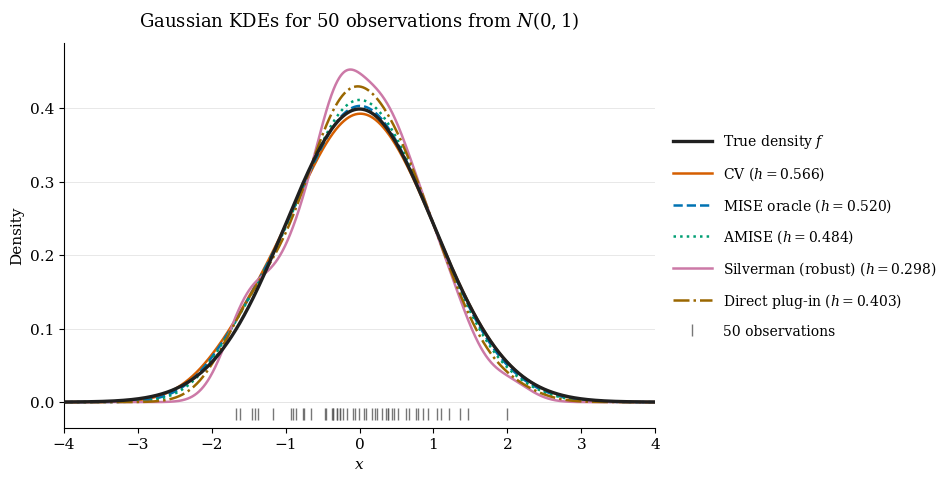

PDF directory: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/classical_bandwidth_kde_illustration
PNG preview: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/classical_bandwidth_kde_illustration/classical_bandwidth_kde_illustration.png


In [5]:
with plt.rc_context({
    "font.family": "serif", "font.size": 11,
    "mathtext.fontset": "dejavuserif", "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
}):
    fig, ax = plt.subplots(figsize=(9.4, 4.7), layout="constrained")
    ax.plot(x_grid, true_density, color="#202020", linewidth=2.4,
            label=r"True density $f$", zorder=6)
    colors = ["#D55E00", "#0072B2", "#009E73", "#CC79A7", "#9A6700"]
    line_styles = ["-", "--", ":", "-", "-."]
    for method, h, values, color, style in zip(
        method_names, bandwidths, density_values, colors, line_styles
    ):
        ax.plot(x_grid, values, color=color, linestyle=style, linewidth=1.8,
                label=method + f" ($h={h:.3f}$)")

    density_maximum = max(float(true_density.max()), float(density_values.max()))
    rug_height = 0.035 * density_maximum
    ax.plot(samples, np.full(n, -rug_height), linestyle="none", marker="|",
            markersize=9, markeredgewidth=1.0, color="#555555", alpha=0.8,
            label=f"{n} observations", clip_on=False)
    ax.axhline(0.0, color="#999999", linewidth=0.65, zorder=0)
    ax.set(xlim=(-plot_half_width, plot_half_width),
           ylim=(-2.2 * rug_height, 1.08 * density_maximum),
           xlabel=r"$x$", ylabel="Density")
    ax.set_title(f"Gaussian KDEs for {n} observations from " + r"$N(0,1)$",
                 fontsize=13, pad=12)
    ax.grid(axis="y", color="#E8E8E8", linewidth=0.7, zorder=0)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
              fontsize=10, handlelength=2.8, labelspacing=1.0, borderaxespad=0.0)
    png_path = image_directory / f"{notebook_name}.png"
    fig.savefig(png_path, dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()  # The shared exporter automatically saves the PDF here.
    plt.close(fig)
print(f"PDF directory: {pdf_output_directory}")
print(f"PNG preview: {png_path}")

from kde_tools.thesis_exports import copy_thesis_pdf
if n == 50:
    copy_thesis_pdf(pdf_output_directory, "classical_bandwidth_kde_illustration",
        "001_gaussian_kdes_for_50_observations_from_n_0_1.pdf")
